What is the most optimal skill to learn for Data Analysts?
Methodology
1.Continue from last notebook to find percent of postings with skill
2.Visualize median salary vs percent skill demand
3.(Optional) Determine if certain technologies are more prevalent

In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df_DA_US =df[(df['job_title_short']== 'Data Analyst') &(df['job_country']=='United States')].copy()

In [3]:
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US_exploded = df_DA_US.explode('job_skills')
df_DA_US_exploded[['job_skills', 'salary_year_avg']].head()


,job_skills,salary_year_avg
109,python,89000.0
109,r,89000.0
109,alteryx,89000.0
109,tableau,89000.0
180,excel,90250.0


In [4]:
df_DA_skills = df_DA_US_exploded.groupby('job_skills')['salary_year_avg'].agg(['median', 'count']).sort_values(by= 'count', ascending=False)
#rename columns name
df_DA_skills = df_DA_skills.rename(columns={'median' : 'median_salary', 'count' : 'skill_count'})
DA_job_count = len(df_DA_US)
df_DA_skills['skill_percent'] = df_DA_skills['skill_count']/ DA_job_count*100
skill_percent = 5 
df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] > skill_percent ]
df_DA_skills_high_demand


,median_salary,skill_count,skill_percent
job_skills,,,
sql,91000.00,2508,57.655172
excel,84392.00,1808,41.563218
python,97500.00,1431,32.896552
tableau,92875.00,1364,31.356322
sas,90000.00,926,21.287356
r,92500.00,893,20.528736
power bi,90000.00,838,19.264368
powerpoint,85000.00,462,10.620690
word,81194.75,461,10.597701


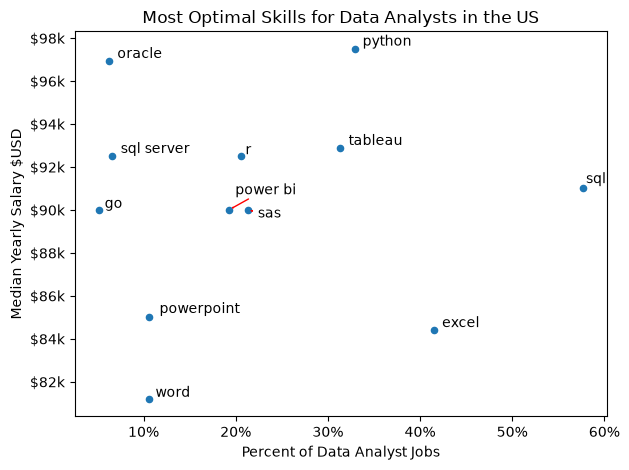

In [5]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter
df_DA_skills_high_demand.plot(kind = 'scatter', x = 'skill_percent' , y = 'median_salary')
plt.ylabel('Median Yearly Salary $USD')
plt.xlabel('Percent of Data Analyst Jobs')
plt.title('Most Optimal Skills for Data Analysts in the US')
# Format axis 
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y , pos : f'${int(y/1000)}k'))
plt.gca().xaxis.set_major_formatter(PercentFormatter(decimals =0)) 
#text: Add text annotations to the plot by using for loop 
texts =[]
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], " " + txt))
# Adjust text to avoid overlap and add arrows
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='red'))

plt.tight_layout()
plt.show()

In [10]:
df_technology = df['job_type_skills'].copy()
#Remove duplicates
df_technology = df_technology.drop_duplicates()
#Remove NAN values
df_technology = df_technology.dropna()
# combine all dictionaries into one
technology_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row)  # convert string to dictionary
    for key, value in row_dict.items():
        if key in technology_dict:  # if key already exists in technology_dict, add value to existing value
            technology_dict[key] += value
        else:                       # if key does not exist in technology_dict, add key and value
            technology_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['excel',
  'spreadsheet',
  'sas',
  'spss',
  'microstrategy',
  'ssrs',
  'looker',
  'powerpoint',
  'ssis',
  'datarobot',
  'qlik',
  'msaccess',
  'outlook',
  'esquisse',
  'sheets',
  'cognos',
  'dax',
  'sharepoint',
  'splunk',
  'power bi',
  'visio',
  'sap',
  'nuix',
  'powerbi',
  'word',
  'ms access',
  'alteryx',
  'tableau'],
 'programming': ['html',
  'delphi',
  'mongodb',
  'sas',
  'shell',
  'c',
  'c#',
  'scala',
  'swift',
  'solidity',
  'r',
  'java',
  'vb.net',
  'matlab',
  'sql',
  'sass',
  'groovy',
  'pascal',
  'css',
  'haskell',
  'mongo',
  'javascript',
  'crystal',
  'python',
  'c++',
  'go',
  'nosql',
  'visual basic',
  'php',
  'kotlin',
  'cobol',
  'typescript',
  'bash',
  'fortran',
  'perl',
  'visualbasic',
  'clojure',
  'julia',
  'golang',
  'f#',
  'erlang',
  'assembly',
  'apl',
  'rust',
  'ruby',
  'no-sql',
  'lisp',
  'ocaml',
  'dart',
  'lua',
  't-sql',
  'vba',
  'objective-c',
  'elixir',
  'powersh

In [11]:
# turn dictionary into dataframe
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,excel
0,analyst_tools,spreadsheet
0,analyst_tools,sas
0,analyst_tools,spss
0,analyst_tools,microstrategy
...,...,...
9,sync,wire
9,sync,google chat
9,sync,microsoft teams
9,sync,mattermost


In [12]:
# merge df_DA_skills and df_technology
df_DA_skills_tech = df_DA_skills.merge(df_technology, left_on='job_skills', right_on='skills')

df_DA_skills_tech

,median_salary,skill_count,skill_percent,technology,skills
0,91000.0,2508,57.655172,programming,sql
1,84392.0,1808,41.563218,analyst_tools,excel
2,97500.0,1431,32.896552,programming,python
3,92875.0,1364,31.356322,analyst_tools,tableau
4,90000.0,926,21.287356,analyst_tools,sas
...,...,...,...,...,...
169,100000.0,1,0.022989,libraries,theano
170,65000.0,1,0.022989,programming,typescript
171,147500.0,1,0.022989,cloud,vmware
172,65000.0,1,0.022989,webframeworks,vue


In [14]:
df_DA_plot= df_DA_skills_tech[df_DA_skills_tech['skill_percent'] > skill_percent]

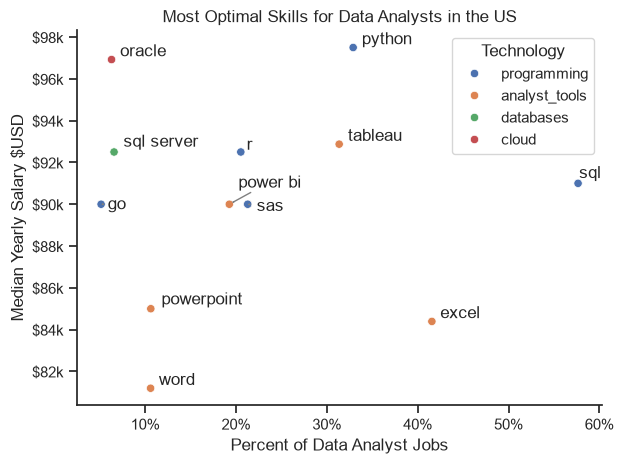

In [16]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter
sns.scatterplot(data=df_DA_plot, x='skill_percent',y='median_salary',hue='technology')
sns.despine()
sns.set_theme(style='ticks')
plt.legend(title='Technology')
plt.ylabel('Median Yearly Salary $USD')
plt.xlabel('Percent of Data Analyst Jobs')
plt.title('Most Optimal Skills for Data Analysts in the US')
# Format axis 
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y , pos : f'${int(y/1000)}k'))
plt.gca().xaxis.set_major_formatter(PercentFormatter(decimals =0)) 
#text: Add text annotations to the plot by using for loop 
texts =[]
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], " " + txt))
# Adjust text to avoid overlap and add arrows
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

plt.tight_layout()
plt.show()